# Zero-Shot Prediction Using Pretrained Genomic LLMs

---

## Learning Outcomes

By the end of this session, participants will be able to:
- Compute zero-shot variant effect predictions using pretrained genomic LLMs
- Visualise and verify the predictions

### Example: Zero-shot prediction of DNA mutation effects using Mistral-DNA
*This tutorial is based on some fantastic materials created by Prof. Raphael Mourad at the University Paul Sabatier in Toulouse, France. You can find the full tutorial and lecture notes in his GitHub repository here: https://github.com/raphaelmourad/LLM-for-genomics-training.*

First, let's clone the GitHub repository for the model:

In [19]:
!git clone https://github.com/raphaelmourad/Mistral-DNA.git

fatal: destination path 'Mistral-DNA' already exists and is not an empty directory.


Then, we need to install and import the required libraries.

In [20]:
# Loads pretrained DNA model and tokenizer
!pip install -q "transformers==4.57.6" --force-reinstall

ERROR: Operation cancelled by user


In [21]:
!pip install Bio==1.7.1 --q --force-reinstall

Traceback (most recent call last):
  File "/usr/local/bin/pip3", line 4, in <module>
    from pip._internal.cli.main import main
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/main.py", line 11, in <module>
    from pip._internal.cli.autocompletion import autocomplete
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/autocompletion.py", line 10, in <module>
    from pip._internal.cli.main_parser import create_main_parser
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/main_parser.py", line 9, in <module>
    from pip._internal.build_env import get_runnable_pip
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/build_env.py", line 21, in <module>
    from pip._internal.metadata import get_default_environment, get_environment
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/metadata/__init__.py", line 9, in <module>
    from .base import BaseDistribution, BaseEnvironment, FilesystemWheel, MemoryWheel, Wheel
  Fi

In [22]:
!pip install seaborn
!pip install tensorflow

**Remember to restart the runtime after the installs**

In [23]:
# Import required libraries
import torch # Runs model and performs tensor calculations
import tensorflow as tf
import numpy as np # Performs numerical operations, including distances
import scipy as sp # Scientific computing

import gzip
from Bio import SeqIO # Reads biological sequence files
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer
from transformers import AutoModelForMaskedLM, AutoModelForCausalLM, AutoConfig

#### Helper functions
Let's define a few helper functions to aid with the task.

In [24]:
# Function to read FASTA files
# Reads DNA sequence from a compressed FASTA file (.fasta.gz)

def readRegularFastaFile(fasta_file):
	seql_list=[] # empty list to store parsed DNA sequences as text strings

	# Opens compressed .gz file in read text(rt) (text file)
	with gzip.open(fasta_file, "rt") as handle:
		# Read FASTA records using Biopython's seq10 module
			for record in SeqIO.parse(handle, "fasta"):
					# Loops through every biological record in the file, retrieves the sequence and converts into a python string
					seqj=str(record.seq)

		 			# Appends parsed DNA string to sequence list
					seql_list.append(seqj)

# Return final list containing all DNA sequences
	return seql_list

Now we need to load the model and tokeniser.

In [25]:
# Define our model path: https://huggingface.co/RaphaelMourad/Mistral-DNA-v1-17M-hg38
#hg38: GRCh38, digital nucleic acid sequence database - representative standard reference for the human genome

MODEL_PATH = "RaphaelMourad/Mistral-DNA-v1-17M-hg38"

In [26]:
# LOAD TOKENIZER
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH,
    padding_side="left", # Here, the model was trained with padding_side="left"
    use_fast=True, # laod optimised, fast tokeniser instead of Python/NumPy slow version
    trust_remote_code=True, # Allows custom Python code supplied w the model to be used when loading its tokenizer
)

In [27]:
# LOAD MODEL

 # AutoModelForCausalLM: causal LM - trained to predict the next token based on the tokens that came before it

model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH,
)
model.config.pad_token_id = tokenizer.pad_token_id
model

MixtralForCausalLM(
  (model): MixtralModel(
    (embed_tokens): Embedding(4096, 256)
    (layers): ModuleList(
      (0-7): 8 x MixtralDecoderLayer(
        (self_attn): MixtralAttention(
          (q_proj): Linear(in_features=256, out_features=256, bias=False)
          (k_proj): Linear(in_features=256, out_features=256, bias=False)
          (v_proj): Linear(in_features=256, out_features=256, bias=False)
          (o_proj): Linear(in_features=256, out_features=256, bias=False)
        )
        (block_sparse_moe): MixtralSparseMoeBlock(
          (gate): Linear(in_features=256, out_features=8, bias=False)
          (experts): ModuleList(
            (0-7): 8 x MixtralBlockSparseTop2MLP(
              (w1): Linear(in_features=256, out_features=256, bias=False)
              (w2): Linear(in_features=256, out_features=256, bias=False)
              (w3): Linear(in_features=256, out_features=256, bias=False)
              (act_fn): SiLUActivation()
            )
          )
        )
  

In [28]:
# NUMBER OF MODEL PARAMETERS

# For each parameter tensor in the model, call numel , produce its element count and sum()

pytorch_total_params = sum(
    # numel: total number of elements
    # model.parameters() PyTorch method
    p.numel() for p in model.parameters()
    )

# Divide parameter count by 1000^2 (1 mill) = converts count into millions
# .1f format to 1 decimal place
print(f"Model size: {pytorch_total_params/1000**2:.1f}M parameters")

Model size: 16.8M parameters


#### Compute sequence embeddings
For a model to be able to process a sequence, it must be converted into a vector of numbers. These vectors are called *embeddings*.

More information on LLM embeddings: https://huggingface.co/spaces/hesamation/primer-llm-embedding?section=what_are_embeddings?

Let's generate the embeddings for a sample DNA sequence.

In [29]:
dna = "ACGTAGCATCGGATCTATCTATCGACACTTGGTTATCGATCTACGAGCATCTCGTTAGC" # Our sample DNA sequence

# Tokeniser takes raw dna text string > splits into tokens
# return_tensors = 'pt' : return as PyTorch tensors
#["input_ids"]: view only token ids from tokenizers output
inputs = tokenizer(dna, return_tensors = 'pt')["input_ids"]
print(f"Inputs: {inputs}")

# Model(inputs) runs tokenised inputs through the transformer model
# Index 0 in this model is the tensor of output logits
# .detach() disconnects tensor from the computational graph as we r not training
hidden_states = model(inputs)[0].detach()
print(f"Hidden states: {hidden_states}")

#POOLING: produce one representative vector for entire sequence

# Embedding with mean pooling
# Avg activation pattern across the sequence
embedding_mean = torch.mean(hidden_states[0], dim=0)
print(f"Shape of embedding with mean pooling: {embedding_mean.shape}")

# Embedding with max pooling
# Largest value of each feature, steongest activation across positions
embedding_max = torch.max(hidden_states[0], dim=0)[0]
print(f"Shape of embedding with max pooling: {embedding_max.shape}")

Inputs: tensor([[   1,    5,  194,   32,  757, 1239, 2092,  294,   24,  359,   88,   93,
           32,   75,   77,   19,    2]])
Hidden states: tensor([[[-5.7822, -2.6941,  0.2004,  ..., -0.8346, -0.4331, -2.4413],
         [-5.9302, -3.0826, -1.7779,  ..., -0.4484, -0.2522, -1.7841],
         [-6.4070, -3.5369, -0.8623,  ..., -0.4834, -0.2303, -1.4513],
         ...,
         [-6.7136, -4.0397, -0.2811,  ...,  0.0941,  0.0367, -1.0994],
         [-4.1983, -0.5584,  7.8823,  ..., -1.6618, -5.4440, -4.1521],
         [-6.5815, -4.2742, -0.0318,  ..., -0.2478, -2.5161, -0.3905]]])
Shape of embedding with mean pooling: torch.Size([4096])
Shape of embedding with max pooling: torch.Size([4096])


#### Compute cystic fibrosis mutation effect (Gene: CFTR)
1. Get the wild-type and mutated versions of the sample sequence
2. Tokenise both sequences
3. Get the hidden states of the sequences
4. Calculate the embeddings from the hidden states
5. Get the L2 distance between the embeddings of the wild-type and mutated sequences -> this is the (unnormalised) mutation effect

**Case 1: Impactful mutation**

Higher L2 distance = CTTT deletion causes significant structural/functional alteration in how the genomic LLM perceives the sequence


In [30]:
dna_wt= "ATTAAAGAAAATATCATCTTTGGTGTTTCCTAT"
dna_mut="ATTAAAGAAAATATCATTGGTGTTTCCTAT" # The mutation here is the deletion of CTTT

# Tokenise both sequences and process as a single batch, return as PyTorch tensors
# padding=True: add padding tokens bc mutated seq is shorter
inputs_seqs = tokenizer([dna_wt,dna_mut], return_tensors = 'pt', padding=True)["input_ids"]
# Passes batched input tensors into the model and retrieves hidden states for both sequences
hidden_states_seqs = model(inputs_seqs)[0].detach()

# Max pooling
# hidden_states_seqs 3 dimensions: [number of sequences(2), no. tokens in each sequence, no. features per token]
# dim=1, take max of each feature across tokens = produce 1 dimension per sequence
embedding_max = torch.max(hidden_states_seqs, dim=1)[0]
print(embedding_max)

# torch.norm() function calculates numerical norm of a PyTorch tensor
# Calculates L2 distance between embeddings of wt and mut DNA = quantify impact of mutation
distL2=torch.norm(embedding_max[0]-embedding_max[1])
print(distL2) # Mutation effect (unnormalised)

tensor([[-5.6724, -2.3842,  5.1578,  ...,  1.9340,  1.4729,  3.9054],
        [-2.0535,  0.7848,  4.8104,  ...,  0.7478,  0.9392,  1.6499]])
tensor(145.7797)


**Case 2: Non-impactful mutation**

In [31]:
dna_wt= "ATTAAAGAAAATATCATCTTTGGTGTTTCCTAT" # ATT = Isoleucine
dna_mut="ATAAAAGAAAATATCATCTTTGGTGTTTCCTAT" # ATA = Isoleucine (encode same amino acid)

inputs_seqs = tokenizer([dna_wt,dna_mut], return_tensors = 'pt', padding=True)["input_ids"]
hidden_states_seqs = model(inputs_seqs)[0].detach() # [1, sequence_length, 768]

embedding_max = torch.max(hidden_states_seqs, dim=1)[0]
print(embedding_max)

distL2=torch.norm(embedding_max[0]-embedding_max[1])
print(distL2) # Mutation effect (unnormalised)

tensor([[-5.6724, -2.3842,  5.1578,  ...,  1.9340,  1.4729,  3.9054],
        [-5.5415, -2.3247,  5.0079,  ...,  1.9292,  1.7426,  3.8457]])
tensor(27.4657)


We can see that the impactful mutation produces a higher value than the non-impactful mutation, i.e., higher impact == higher mutation effect score.

#### Compute and compare the impacts of SNPs in introns vs exons

Analyse many mutations at once

SNP: variation at one nucleotide position eg. A > G

In [32]:
# Load all SNPs
# Load 4 files: exon ref and alt sequences, intro ref and alt sequences
file_SNPexon_ref="Mistral-DNA/data/SNP/SNPexon_ref_201b.fasta.gz"
file_SNPexon_alt="Mistral-DNA/data/SNP/SNPexon_alt_201b.fasta.gz"
file_SNPintron_ref="Mistral-DNA/data/SNP/SNPintron_ref_201b.fasta.gz"
file_SNPintron_alt="Mistral-DNA/data/SNP/SNPintron_alt_201b.fasta.gz"

# Let's use 100 sequences to speed things up
kseq=100

exon_ref_seq=readRegularFastaFile(file_SNPexon_ref)[0:kseq]
exon_alt_seq=readRegularFastaFile(file_SNPexon_alt)[0:kseq]
intron_ref_seq=readRegularFastaFile(file_SNPintron_ref)[0:kseq]
intron_alt_seq=readRegularFastaFile(file_SNPintron_alt)[0:kseq]

Let's define a function to compute the embeddings of the DNA sequences.

In [33]:
def compEmbed(seq_list): # Input: list of sequences

  inputs_seqs = tokenizer( # Tokenise the input sequences
      seq_list,
      return_tensors = 'pt', # Return as Pytorch tensor
      padding=True)["input_ids"] # Pad sequences to common length

# Pass batch of tokenised sequences into model, retrieves hidden states
  hidden_states_seqs = model(inputs_seqs)[0].detach().cpu().float().numpy() # Get the hidden states
  # .detach() removes tensor from PyTroch automatic differentitation graph
  # .cpu() moves tensor from GPU memory back to standard system memory: free up GPU memory
  # .float() format as float32
  # .numpy() converts PyTorch tensor into NumPy array: downstream functions/libraries

  embedding_max = np.max(hidden_states_seqs, axis=1) # Embedding with max pooling
  # Go through every feature dimension across tokens (axis=1), get largest value = single representative array

  return embedding_max

Then, we can use this to define a function to compute the mutation effect.

In [34]:
# Takes 2 sequences (Ref and alt) and calculates their L2 distances

def compMutEffect(seq_ref_list,seq_alt_list): # Input: list of wild-type sequences and list of mutated sequences
  # Call previous function
  embedding_ref = compEmbed(seq_ref_list) # Compute the embeddings of the wild-type sequences
  embedding_alt = compEmbed(seq_alt_list) # Compute the embeddings of the mutated sequences
  distL2 = np.linalg.norm(embedding_alt -embedding_ref, axis=1, ord=2) # Calculate the L2 distances between the embeddings
  return distL2

We will now use this function to calculate the effects of all SNPs in the exons and introns.

In [35]:
distL2_exonSNPs = compMutEffect(exon_ref_seq, exon_alt_seq) # Compute exon SNP effects
distL2_intronSNPs = compMutEffect(intron_ref_seq, intron_alt_seq) # Compute intron SNP effects

Let's create a boxplot of the distributions of exon vs intron SNP effects.

/tmp/ipykernel_3368/4069558079.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(distL2SNPs.keys())


Text(0, 0.5, 'L2 Distance')

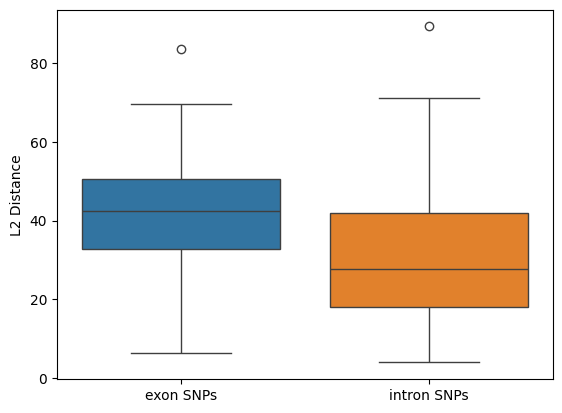

In [36]:
# Dictionary
distL2SNPs = {'exon SNPs': distL2_exonSNPs, 'intron SNPs': distL2_intronSNPs}

# Matplotlib figure and axis
fig, ax = plt.subplots()
# Seaborn library to parse dictionary and plo2 box plots
sns.boxplot(ax=ax, data=distL2SNPs)
# assigns dictionary keys as x labels
ax.set_xticklabels(distL2SNPs.keys())
# y axis label
ax.set_ylabel("L2 Distance")

We see that the L2 distance is higher for SNPs in exons compared to SNPs in introns. This is expected, as SNPs in exons are expected to have a greater impact.

Refresher on exons and introns: https://dnalc.cshl.edu/view/15549-Transcription-translation-Exons-and-introns.html, https://www.cd-genomics.com/blog/introns-and-exons/.

*In most eukaryotic genes, coding regions (exons) are interrupted by noncoding regions (introns). During transcription, the entire gene is copied into a pre-mRNA, which includes exons and introns. During the process of RNA splicing, introns are removed and exons joined to form a contiguous coding sequence. This "mature" mRNA is ready for translation.

### Try it yourself: Zero-shot prediction of mutation effects using Nucleotide Transformer

In [37]:
MODEL_NAME = "InstaDeepAI/nucleotide-transformer-v2-50m-multi-species"
model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME, trust_remote_code=True)

In [38]:
# Load tokeniser
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    padding_side = "left",
    use_fast = True,
    trust_remote_code=True,
)

##### Solution

In [39]:
# Load tokeniser
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    padding_side="left", # Here, the model was trained with padding_side="left"
    use_fast=True,
    trust_remote_code=True,
)

#### Compute cystic fibrosis mutation effect (Gene: CFTR)
1. Get the wild-type and mutated versions of the sample sequence
2. Tokenise both sequences
3. Get the hidden states of the sequences
4. Calculate the embeddings from the hidden states
5. Get the L2 distance between the embeddings of the wild-type and mutated sequences -> this is the (unnormalised) mutation effect

##### **Case 1: Impactful mutation**

In [41]:
dna_wt= "ATTAAAGAAAATATCATCTTTGGTGTTTCCTAT"
dna_mut="ATTAAAGAAAATATCATTGGTGTTTCCTAT" # The mutation here is the deletion of CTTT

inputs_seqs = tokenizer([dna_wt,dna_mut], return_tensors = 'pt', padding=True)["input_ids"]
hidden_states_seqs = model(inputs_seqs)[0].detach()

embedding_max = torch.max(hidden_states_seqs, dim=1)[0]
print(embedding_max)

distL2 = torch.norm(embedding_max[0] - embedding_max[1])
print(distL2) # Mutation effect (unnormalised)

tensor([[-9.2201, -9.6858, -9.8567,  ..., 12.1464, 15.9689, 14.5510],
        [-9.8340, -9.2863, -9.3982,  ..., -0.3090,  0.9604,  4.2570]])
tensor(178.2122)


###### Solution

In [ ]:
dna_wt= "ATTAAAGAAAATATCATCTTTGGTGTTTCCTAT"
dna_mut="ATTAAAGAAAATATCATTGGTGTTTCCTAT" # The mutation here is the deletion of CTTT

inputs_seqs = tokenizer([dna_wt,dna_mut], return_tensors = 'pt', padding=True)["input_ids"]
hidden_states_seqs = model(inputs_seqs)[0].detach()

embedding_max = torch.max(hidden_states_seqs, dim=1)[0]
print(embedding_max)

distL2=torch.norm(embedding_max[0]-embedding_max[1])
print(distL2) # Mutation effect (unnormalised)

##### **Case 2: Non-impactful mutation**

In [42]:
dna_wt= "ATTAAAGAAAATATCATCTTTGGTGTTTCCTAT" # ATT = Isoleucine
dna_mut="ATAAAAGAAAATATCATCTTTGGTGTTTCCTAT" # ATA = Isoleucine

inputs_seqs = tokenizer([dna_wt,dna_mut], return_tensors = 'pt', padding=True)["input_ids"]
hidden_states_seqs = model(inputs_seqs)[0].detach() # [1, sequence_length, 768]

embedding_max = torch.max(hidden_states_seqs, dim=1)[0]
print(embedding_max)

distL2 = torch.norm(embedding_max[0] - embedding_max[1])
print(distL2) # Mutation effect (unnormalised)

tensor([[-9.2201, -9.6858, -9.8567,  ..., 12.1464, 15.9689, 14.5510],
        [-9.7009, -9.7375, -9.3364,  ..., 12.7865, 15.8241, 14.8497]])
tensor(62.2222)


###### Solution

In [ ]:
dna_wt= "ATTAAAGAAAATATCATCTTTGGTGTTTCCTAT" # ATT = Isoleucine
dna_mut="ATAAAAGAAAATATCATCTTTGGTGTTTCCTAT" # ATA = Isoleucine

inputs_seqs = tokenizer([dna_wt,dna_mut], return_tensors = 'pt', padding=True)["input_ids"]
hidden_states_seqs = model(inputs_seqs)[0].detach() # [1, sequence_length, 768]

embedding_max = torch.max(hidden_states_seqs, dim=1)[0]
print(embedding_max)

distL2=torch.norm(embedding_max[0]-embedding_max[1])
print(distL2) # Mutation effect (unnormalised)

##### **What do you notice about the difference in the L2 norm for the impactful vs non-impactful mutation?**

### Extracting embeddings from intermediate layers

*extract representations from intermediate layers of the msitral-DNA model, rather than just usinf the final output layer

In [43]:
import torch
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("RaphaelMourad/Mistral-DNA-v1-17M-hg38", trust_remote_code=True)
model = AutoModel.from_pretrained(
    "RaphaelMourad/Mistral-DNA-v1-17M-hg38",
    trust_remote_code=True,
    output_hidden_states=True # Return hidden states from its embedding output and layers, not just final year
)
# Evaluation mode, disables training behaviours
model.eval()


dna = "TGATGATTGGCGCGGCTAGGATCGGCT"
# Tokenize DNA strings, return as PyTorch tensors, view token ids from tokenizers output
inputs = tokenizer(dna, return_tensors="pt")["input_ids"]

# prevents gradient calculations, saving memory when we're only doing inference
with torch.no_grad():
    outputs = model(inputs)

# outputs.hidden_states is a tuple containing representations from embedding ouput and each model layer:
# (embedding_output, layer_1, layer_2, ..., layer_N)
hidden_states = outputs.hidden_states
print(f"Number of layers (including embedding output): {len(hidden_states)}")

#i: index, h: item at that position (hidden state tensor)
for i, h in enumerate(hidden_states):
    print(i, h.shape)

# Pick an intermediate layer, e.g. layer 6 out of N
layer_idx = 2
intermediate_layer = hidden_states[layer_idx]  # [1, seq_len, hidden_dim]

# Pool it down to a single embedding (max pooling, per the model card's convention)
embedding_max = torch.max(intermediate_layer[0], dim=0)[0]
print(embedding_max.shape)  # [hidden_dim]

Number of layers (including embedding output): 9
0 torch.Size([1, 9, 256])
1 torch.Size([1, 9, 256])
2 torch.Size([1, 9, 256])
3 torch.Size([1, 9, 256])
4 torch.Size([1, 9, 256])
5 torch.Size([1, 9, 256])
6 torch.Size([1, 9, 256])
7 torch.Size([1, 9, 256])
8 torch.Size([1, 9, 256])
torch.Size([256])
